In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv('Crop Prediction dataset.csv')

In [3]:
df

,State_Name,District_Name,Crop_Year,Season,Crop,Temperature,Humidity,Soil_Moisture,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,36,35,45,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,37,40,46,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,36,41,50,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,37,42,55,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,36,40,54,720.0,165.0
...,...,...,...,...,...,...,...,...,...,...
49994,Chhattisgarh,JANJGIR-CHAMPA,2006,Kharif,Small millets,36,35,45,27.0,7.0
49995,Chhattisgarh,JANJGIR-CHAMPA,2006,Kharif,Soyabean,37,40,46,27.0,32.0
49996,Chhattisgarh,JANJGIR-CHAMPA,2006,Kharif,Sunflower,36,41,50,450.0,213.0
49997,Chhattisgarh,JANJGIR-CHAMPA,2006,Kharif,Urad,37,42,55,1778.0,309.0


In [4]:
df.drop(columns=['State_Name','District_Name','Season'],axis=1,inplace=True)

In [5]:
df.head()

,Crop_Year,Crop,Temperature,Humidity,Soil_Moisture,Area,Production
0,2000,Arecanut,36,35,45,1254.0,2000.0
1,2000,Other Kharif pulses,37,40,46,2.0,1.0
2,2000,Rice,36,41,50,102.0,321.0
3,2000,Banana,37,42,55,176.0,641.0
4,2000,Cashewnut,36,40,54,720.0,165.0


In [6]:
df.tail()

,Crop_Year,Crop,Temperature,Humidity,Soil_Moisture,Area,Production
49994,2006,Small millets,36,35,45,27.0,7.0
49995,2006,Soyabean,37,40,46,27.0,32.0
49996,2006,Sunflower,36,41,50,450.0,213.0
49997,2006,Urad,37,42,55,1778.0,309.0
49998,2006,Gram,36,40,54,216.0,194.0


In [7]:
df.isnull().sum()

Crop_Year          0
Crop               0
Temperature        0
Humidity           0
Soil_Moisture      0
Area               0
Production       215
dtype: int64

In [8]:
df.dropna(inplace=True)

In [9]:
df.isnull().sum()

Crop_Year        0
Crop             0
Temperature      0
Humidity         0
Soil_Moisture    0
Area             0
Production       0
dtype: int64

In [10]:
df.duplicated().sum()

123

In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df.duplicated().sum()

0

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49661 entries, 0 to 49998
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Crop_Year      49661 non-null  int64  
 1   Crop           49661 non-null  object 
 2   Temperature    49661 non-null  int64  
 3   Humidity       49661 non-null  int64  
 4   Soil_Moisture  49661 non-null  int64  
 5   Area           49661 non-null  float64
 6   Production     49661 non-null  float64
dtypes: float64(2), int64(4), object(1)
memory usage: 3.0+ MB


In [14]:
df.describe()

,Crop_Year,Temperature,Humidity,Soil_Moisture,Area,Production
count,49661.000000,49661.000000,49661.000000,49661.000000,49661.000000,4.966100e+04
mean,2005.871267,34.446105,44.776464,53.110771,7410.569529,4.142226e+05
std,5.108505,3.497663,6.662440,5.259737,28015.568093,1.234133e+07
min,1997.000000,25.000000,35.000000,45.000000,0.200000,0.000000e+00
25%,2002.000000,34.000000,40.000000,50.000000,79.000000,8.800000e+01
50%,2006.000000,36.000000,42.000000,54.000000,445.000000,6.420000e+02
75%,2010.000000,36.000000,50.000000,55.000000,2581.000000,5.653000e+03
max,2014.000000,37.000000,55.000000,62.000000,877029.000000,7.801620e+08


In [15]:
df['Crop'].value_counts()

Crop
Rice                 3848
Maize                3247
Moong(Green Gram)    2072
Dry chillies         1592
Arhar/Tur            1575
                     ... 
Grapes                 17
Varagu                 13
Peas  (vegetable)       3
other fibres            2
Guar seed               1
Name: count, Length: 80, dtype: int64

In [16]:
df['Crop'].unique()

array(['Arecanut', 'Other Kharif pulses', 'Rice', 'Banana', 'Cashewnut',
       'Coconut ', 'Dry ginger', 'Sugarcane', 'Sweet potato', 'Tapioca',
       'Black pepper', 'Dry chillies', 'other oilseeds', 'Turmeric',
       'Maize', 'Moong(Green Gram)', 'Urad', 'Arhar/Tur', 'Groundnut',
       'Sunflower', 'Bajra', 'Castor seed', 'Cotton(lint)', 'Horse-gram',
       'Jowar', 'Korra', 'Ragi', 'Tobacco', 'Gram', 'Wheat', 'Masoor',
       'Sesamum', 'Linseed', 'Safflower', 'Onion', 'other misc. pulses',
       'Samai', 'Small millets', 'Coriander', 'Potato',
       'Other  Rabi pulses', 'Soyabean', 'Beans & Mutter(Vegetable)',
       'Bhindi', 'Brinjal', 'Citrus Fruit', 'Cucumber', 'Grapes', 'Mango',
       'Orange', 'other fibres', 'Other Fresh Fruits', 'Other Vegetables',
       'Papaya', 'Pome Fruit', 'Tomato', 'Mesta', 'Cowpea(Lobia)',
       'Lemon', 'Pome Granet', 'Sapota', 'Cabbage', 'Rapeseed &Mustard',
       'Peas  (vegetable)', 'Niger seed', 'Bottle Gourd', 'Varagu',
       'Garl

In [17]:
df['Crop']=df['Crop'].str.strip()

In [18]:
df['Crop'].unique()

array(['Arecanut', 'Other Kharif pulses', 'Rice', 'Banana', 'Cashewnut',
       'Coconut', 'Dry ginger', 'Sugarcane', 'Sweet potato', 'Tapioca',
       'Black pepper', 'Dry chillies', 'other oilseeds', 'Turmeric',
       'Maize', 'Moong(Green Gram)', 'Urad', 'Arhar/Tur', 'Groundnut',
       'Sunflower', 'Bajra', 'Castor seed', 'Cotton(lint)', 'Horse-gram',
       'Jowar', 'Korra', 'Ragi', 'Tobacco', 'Gram', 'Wheat', 'Masoor',
       'Sesamum', 'Linseed', 'Safflower', 'Onion', 'other misc. pulses',
       'Samai', 'Small millets', 'Coriander', 'Potato',
       'Other  Rabi pulses', 'Soyabean', 'Beans & Mutter(Vegetable)',
       'Bhindi', 'Brinjal', 'Citrus Fruit', 'Cucumber', 'Grapes', 'Mango',
       'Orange', 'other fibres', 'Other Fresh Fruits', 'Other Vegetables',
       'Papaya', 'Pome Fruit', 'Tomato', 'Mesta', 'Cowpea(Lobia)',
       'Lemon', 'Pome Granet', 'Sapota', 'Cabbage', 'Rapeseed &Mustard',
       'Peas  (vegetable)', 'Niger seed', 'Bottle Gourd', 'Varagu',
       'Garli

In [19]:
mapping = {
    'Arecanut': 0, 'Other Kharif pulses': 1, 'Rice': 2, 'Banana': 3, 'Cashewnut': 4,
    'Coconut': 5, 'Dry ginger': 6, 'Sugarcane': 7, 'Sweet potato': 8, 'Tapioca': 9,
    'Black pepper': 10, 'Dry chillies': 11, 'other oilseeds': 12, 'Turmeric': 13,
    'Maize': 14, 'Moong(Green Gram)': 15, 'Urad': 16, 'Arhar/Tur': 17, 'Groundnut': 18,
    'Sunflower': 19, 'Bajra': 20, 'Castor seed': 21, 'Cotton(lint)': 22, 'Horse-gram': 23,
    'Jowar': 24, 'Korra': 25, 'Ragi': 26, 'Tobacco': 27, 'Gram': 28, 'Wheat': 29,
    'Masoor': 30, 'Sesamum': 31, 'Linseed': 32, 'Safflower': 33, 'Onion': 34,
    'other misc. pulses': 35, 'Samai': 36, 'Small millets': 37, 'Coriander': 38,
    'Potato': 39, 'Other Rabi pulses': 40, 'Soyabean': 41, 'Beans & Mutter(Vegetable)': 42,
    'Bhindi': 43, 'Brinjal': 44, 'Citrus Fruit': 45, 'Cucumber': 46, 'Grapes': 47,
    'Mango': 48, 'Orange': 49, 'other fibres': 50, 'Other Fresh Fruits': 51,
    'Other Vegetables': 52, 'Papaya': 53, 'Pome Fruit': 54, 'Tomato': 55, 'Mesta': 56,
    'Cowpea(Lobia)': 57, 'Lemon': 58, 'Pome Granet': 59, 'Sapota': 60, 'Cabbage': 61,
    'Rapeseed & Mustard': 62, 'Peas (vegetable)': 63, 'Niger seed': 64, 'Bottle Gourd': 65,
    'Varagu': 66, 'Garlic': 67, 'Ginger': 68, 'Oilseeds total': 69, 'Pulses total': 70,
    'Jute': 71, 'Peas & beans (Pulses)': 72, 'Blackgram': 73, 'Paddy': 74,
    'Pineapple': 75, 'Barley': 76, 'Sannhamp': 77, 'Khesari': 78, 'Guar seed': 79
}


In [20]:
df['Crop']=df['Crop'].map(mapping)

In [21]:
df['Crop'].unique()

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
       13., 14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25.,
       26., 27., 28., 29., 30., 31., 32., 33., 34., 35., 36., 37., 38.,
       39., nan, 41., 42., 43., 44., 45., 46., 47., 48., 49., 50., 51.,
       52., 53., 54., 55., 56., 57., 58., 59., 60., 61., 64., 65., 66.,
       67., 68., 69., 70., 71., 72., 73., 74., 75., 76., 77., 78., 79.])

In [22]:
df.head()

,Crop_Year,Crop,Temperature,Humidity,Soil_Moisture,Area,Production
0,2000,0.0,36,35,45,1254.0,2000.0
1,2000,1.0,37,40,46,2.0,1.0
2,2000,2.0,36,41,50,102.0,321.0
3,2000,3.0,37,42,55,176.0,641.0
4,2000,4.0,36,40,54,720.0,165.0


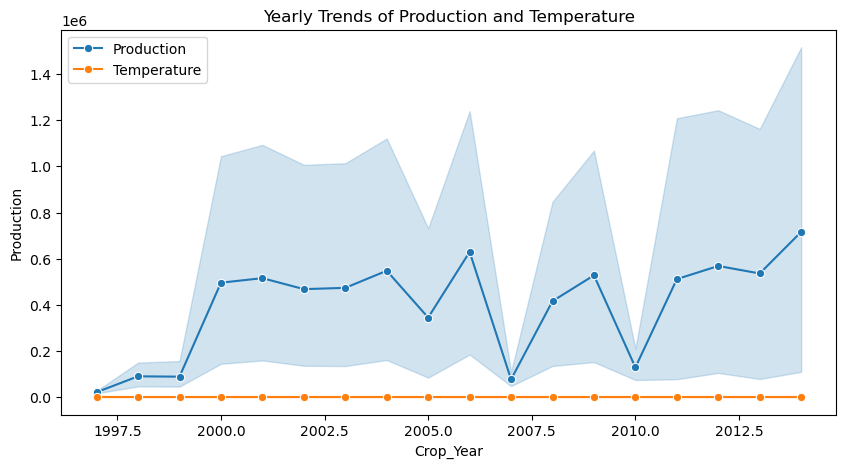

In [23]:
# Line Plot: Trends over the Years
plt.figure(figsize=(10, 5))
sns.lineplot(x='Crop_Year', y='Production', data=df, marker='o', label='Production')
sns.lineplot(x='Crop_Year', y='Temperature', data=df, marker='o', label='Temperature')
plt.title('Yearly Trends of Production and Temperature')
plt.legend()
plt.show()

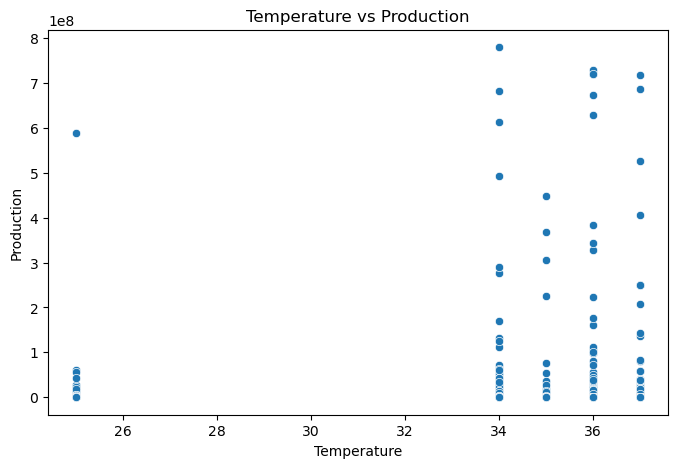

In [24]:
# Scatter Plot: Temperature vs Production
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Temperature', y='Production', data=df)
plt.title('Temperature vs Production')
plt.show()

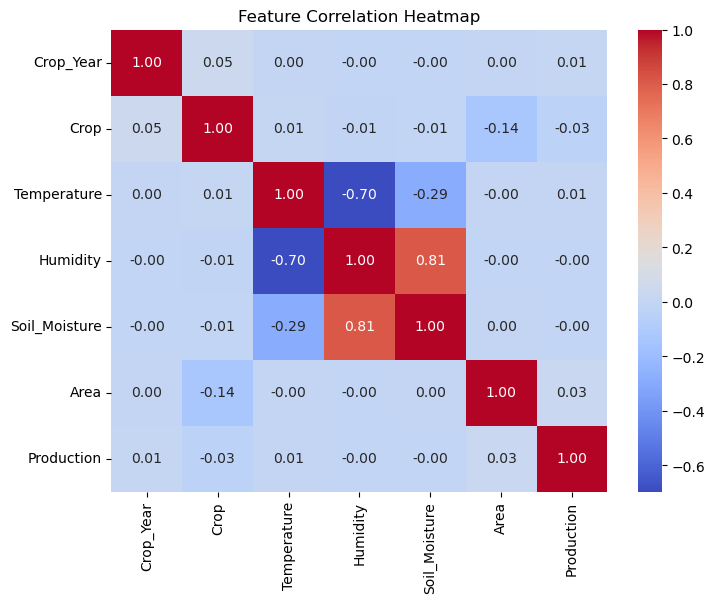

In [25]:
# Heatmap: Feature Correlation
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

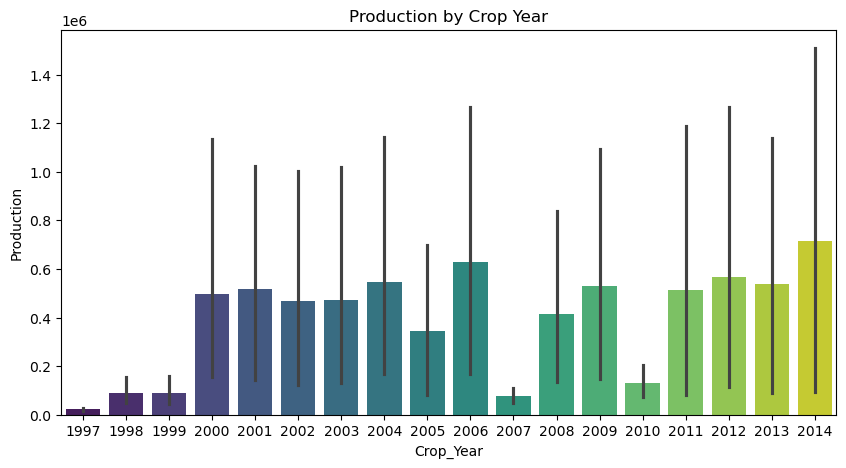

In [26]:
# Bar Plot: Crop Year vs Production
plt.figure(figsize=(10, 5))
sns.barplot(x='Crop_Year', y='Production', data=df, palette='viridis')
plt.title('Production by Crop Year')
plt.show()

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler


#x,y=make_regression(n_samples=5000,n_features=6,random_state=100)

x=df[['Crop_Year','Crop','Temperature','Humidity','Soil_Moisture','Area']]
y=df['Production']


x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

random_forest=RandomForestRegressor()

random_forest.fit(x_train,y_train)

y_pred=random_forest.predict(x_test)

random_forest_r2_score=r2_score(y_test,y_pred)

random_forest_mean_squared_error=mean_squared_error(y_test,y_pred)

print(random_forest_r2_score)
print(random_forest_mean_squared_error)

0.9724743331286481
2051889811060.937


In [28]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.datasets import make_regression
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# Assuming 'df' is already defined and has the relevant columns
x = df[['Crop_Year','Crop','Temperature','Humidity','Soil_Moisture','Area']]
y = df['Production']

# Create regression dataset (you can replace this with your actual dataset)
x, y = make_regression(n_samples=5000, n_features=6, random_state=100)

# Split data into training and testing
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Initialize a Sequential model for the neural network
model = Sequential()

# Add layers to the model (input layer + hidden layers)
model.add(Dense(64, input_dim=x_train.shape[1], activation='relu'))  # Input layer
model.add(Dense(32, activation='relu'))  # Hidden layer
model.add(Dense(16, activation='relu'))  # Hidden layer

# Add output layer
model.add(Dense(1))

# Compile the model with Adam optimizer and Mean Squared Error loss
model.compile(optimizer=Adam(learning_rate=0.001), loss='mean_squared_error')

# Fit the model on the training data
model.fit(x_train, y_train, epochs=20, batch_size=32, verbose=0)

# Predict on the test data
y_pred = model.predict(x_test)

# Calculate R2 Score and Mean Squared Error
xg_r2_score = r2_score(y_test, y_pred)
xg_mean_squared_error = mean_squared_error(y_test, y_pred)

# Print the results
print("Deep Neural Network R2 Score:", xg_r2_score)
print("Deep Neural Network Mean Squared Error:", xg_mean_squared_error)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Deep Neural Network R2 Score: 0.9998649298919726
Deep Neural Network Mean Squared Error: 2.361003810513764


In [29]:
# Save the model to a file (e.g., 'dnn_model.h5')
model.save('dnn_model.h5')


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.datasets import make_regression
import xgboost as xgb
import pandas as pd

# Assuming 'df' is already defined and has the relevant columns
x = df[['Crop_Year','Crop','Temperature','Humidity','Soil_Moisture','Area']]
y = df['Production']

# Create regression dataset (you can replace this with your actual dataset)
#x, y = make_regression(n_samples=5000, n_features=6, random_state=100)

# Split data into training and testing
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Initialize XGBoost Regressor
xg_regressor = xgb.XGBRegressor(objective='reg:squarederror', random_state=42)

# Fit the model on the training data
xg_regressor.fit(x_train, y_train)

# Predict on the test data
y_pred = xg_regressor.predict(x_test)

# Calculate R2 Score and Mean Squared Error
xg_r2_score = r2_score(y_test, y_pred)
xg_mean_squared_error = mean_squared_error(y_test, y_pred)

# Print the results
print("XGBoost R2 Score:", xg_r2_score)
print("XGBoost Mean Squared Error:", xg_mean_squared_error)

XGBoost R2 Score: 0.8748593272454548
XGBoost Mean Squared Error: 9328561323308.32


In [31]:
import pickle
pickle.dump(random_forest,open('model.pkl','wb'))